In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

In [ ]:
from sklearn.metrics import adjusted_rand_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv('final_dataset.csv')
df["gender"] = df["gender"].map({"male": 1, "female": 0})
excluded_columns = ["question_number",	"student_id",	"has_intro", "file_name"]  
df = df.drop(columns=excluded_columns)


In [3]:
df.describe()

,zero_crossing_rate,energy,spectral_centroid,spectral_bandwidth,log_mel_1,log_mel_2,log_mel_3,log_mel_4,log_mel_5,log_mel_6,...,mfcc_12,mfcc_13,spectral_contrast_1,spectral_contrast_2,spectral_contrast_3,spectral_contrast_4,spectral_contrast_5,spectral_contrast_6,spectral_contrast_7,gender
count,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,...,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000,821.000000
mean,0.054954,0.170976,1893.056793,1929.081328,-24.408357,-20.533612,-19.026207,-23.217894,-30.253764,-35.060643,...,-2.817423,-4.180447,17.667740,14.178068,19.442202,19.898673,22.756795,31.342683,31.292369,0.768575
std,0.055693,0.026658,1285.677087,414.365355,11.105592,10.241122,10.655355,11.713222,11.641152,10.884943,...,8.598965,9.469299,3.597710,2.438562,2.943168,2.643634,2.429598,4.304217,6.560196,0.422001
min,0.006679,0.001929,676.703972,1094.504697,-69.511160,-69.631996,-70.493220,-70.769890,-71.311760,-71.659270,...,-32.578854,-30.792100,6.134539,5.500055,7.212382,8.723677,14.126717,15.918311,13.496614,0.000000
25%,0.027361,0.164994,1240.350891,1642.914456,-30.456938,-24.566574,-22.241800,-28.678220,-37.371340,-41.897877,...,-8.758240,-10.399458,15.196449,12.764616,17.941771,18.356203,21.076658,28.461698,27.175248,1.000000
50%,0.035740,0.174484,1482.816332,1859.053958,-22.466913,-18.233969,-15.703797,-21.320694,-29.064032,-34.157158,...,-2.869582,-4.863769,18.348865,14.183379,19.654289,20.060046,22.618777,31.304603,30.850208,1.000000
75%,0.055541,0.184325,1934.814207,2125.475898,-16.285906,-13.515914,-12.299141,-14.575443,-21.959051,-27.073206,...,3.029158,1.903227,20.481872,15.682439,21.421342,21.611011,24.315244,34.211570,35.127551,1.000000
max,0.389508,0.255353,9404.544156,3828.028079,-4.265939,-5.610474,-4.974742,-5.276269,-7.448854,-10.938334,...,24.490343,29.624844,26.220016,22.694689,26.313290,29.945191,31.761034,44.890301,50.992761,1.000000


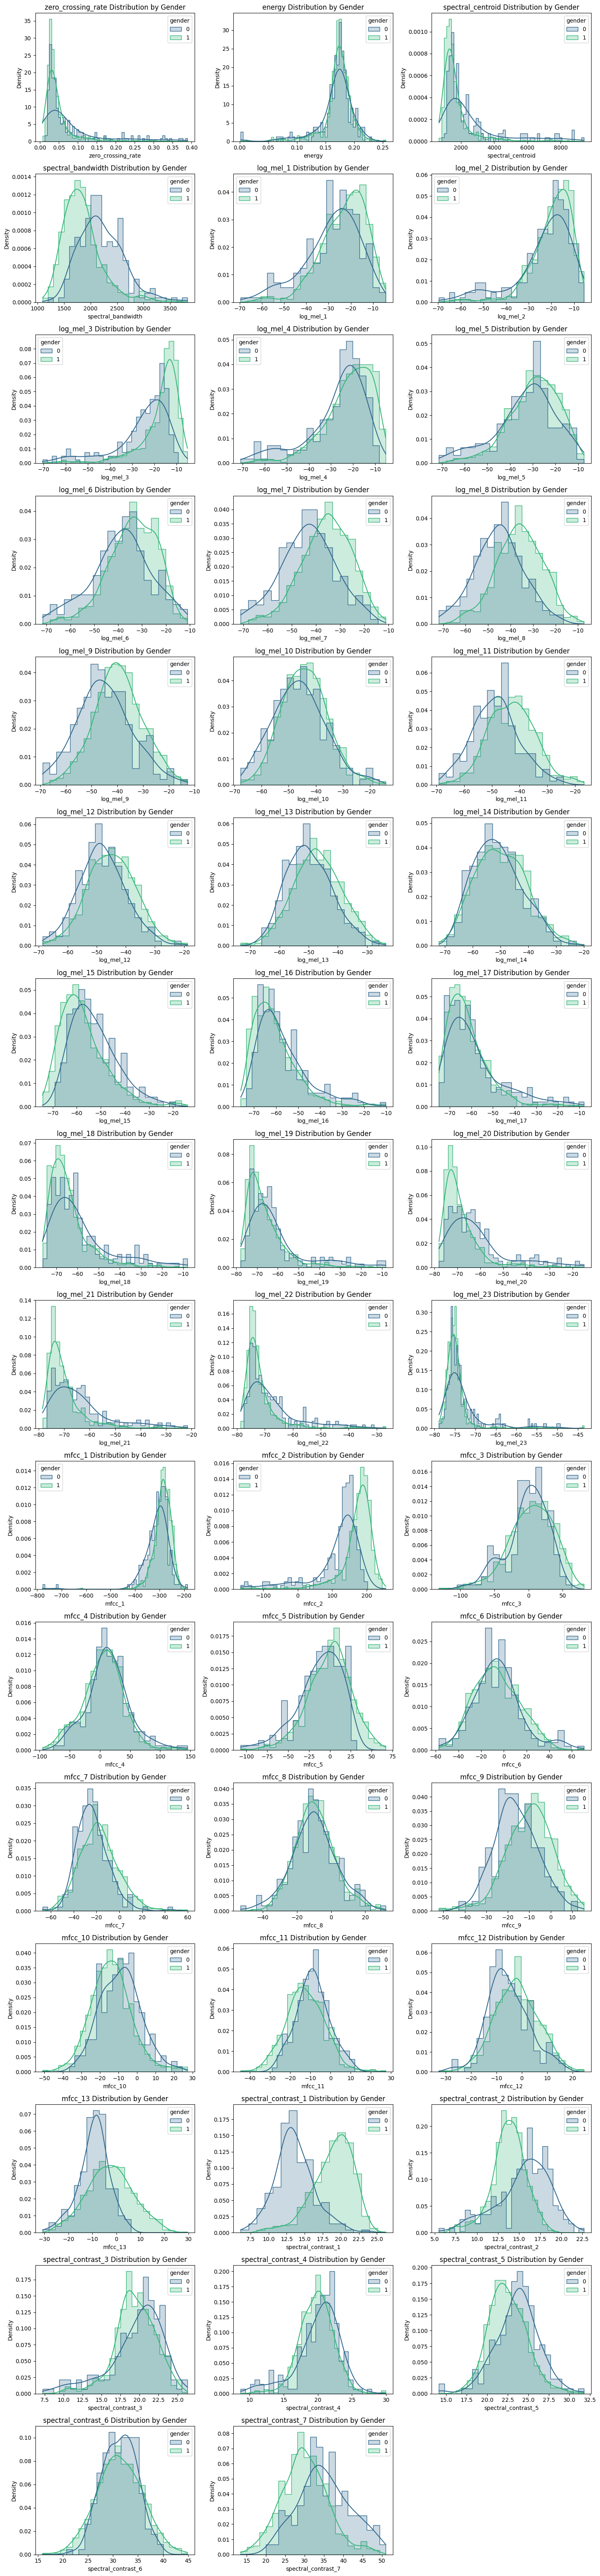

In [ ]:


features_to_plot = [col for col in df.columns if col != "gender"]

n_features = len(features_to_plot)
n_cols = 3  
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten() 

for i, feature in enumerate(features_to_plot):
    sns.histplot(
        data=df,
        x=feature,
        hue='gender',
        kde=True,
        ax=axes[i],
        palette="viridis",
        element="step",  
        stat="density",  
        common_norm=False
    )
    axes[i].set_title(f'{feature} Distribution by Gender')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Density")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


first we do the clustering based on all the features

Adjusted Rand Index: 0.09788098467547311


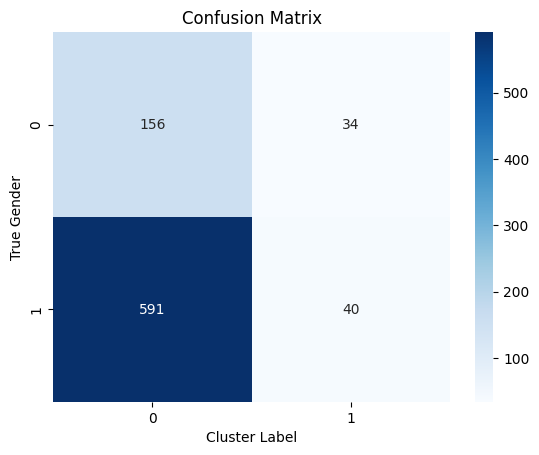

In [28]:
X_selected = df
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)
kmeans = KMeans(n_clusters=2, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)
true_labels = df['gender'] 
ari = adjusted_rand_score(true_labels, cluster_labels)
print("Adjusted Rand Index:", ari)

cm = confusion_matrix(true_labels, cluster_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Cluster Label")
plt.ylabel("True Gender")
plt.title("Confusion Matrix")
plt.show()

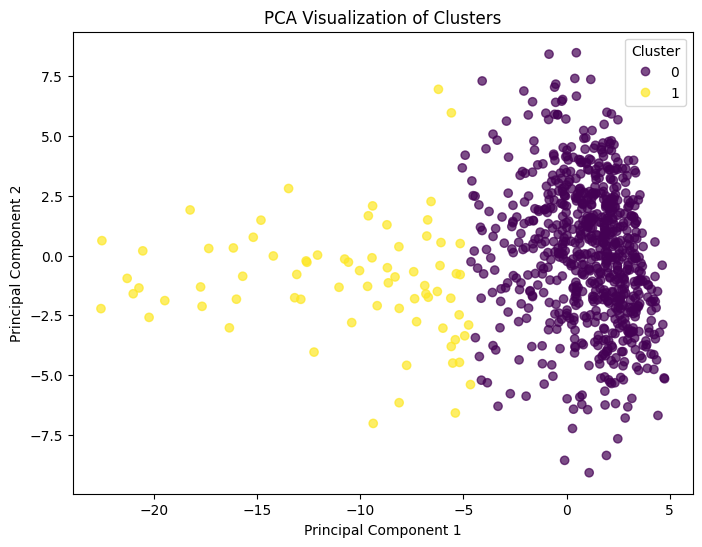

In [29]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Clusters")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()


no we do the clustering on the highest correlated features with the label where the correlation between the features is lower than a certain threshold

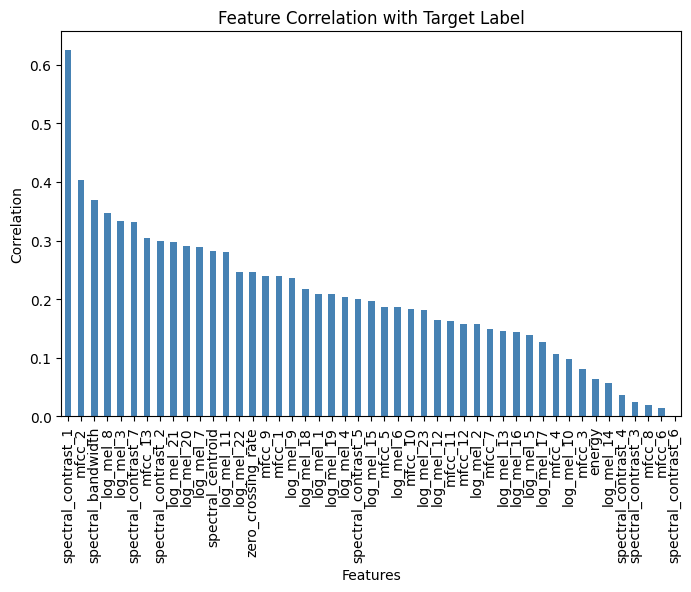

In [5]:
label_correlation = df.corr()["gender"].drop("gender").sort_values(ascending=False)  
abs_correlation = label_correlation.abs()
abs_correlation = abs_correlation.sort_values(ascending=False)
plt.figure(figsize=(8, 5))
abs_correlation.plot(kind="bar", color="steelblue")
plt.title("Feature Correlation with Target Label")
plt.xlabel("Features")
plt.ylabel("Correlation")
plt.xticks(rotation=90)
plt.show()

In [6]:
top_features = abs_correlation.head(10).index.tolist()
X_top = df[top_features]
feature_corr_matrix = X_top.corr().abs()
print(top_features)

['spectral_contrast_1', 'mfcc_2', 'spectral_bandwidth', 'log_mel_8', 'log_mel_3', 'spectral_contrast_7', 'mfcc_13', 'spectral_contrast_2', 'log_mel_21', 'log_mel_20']


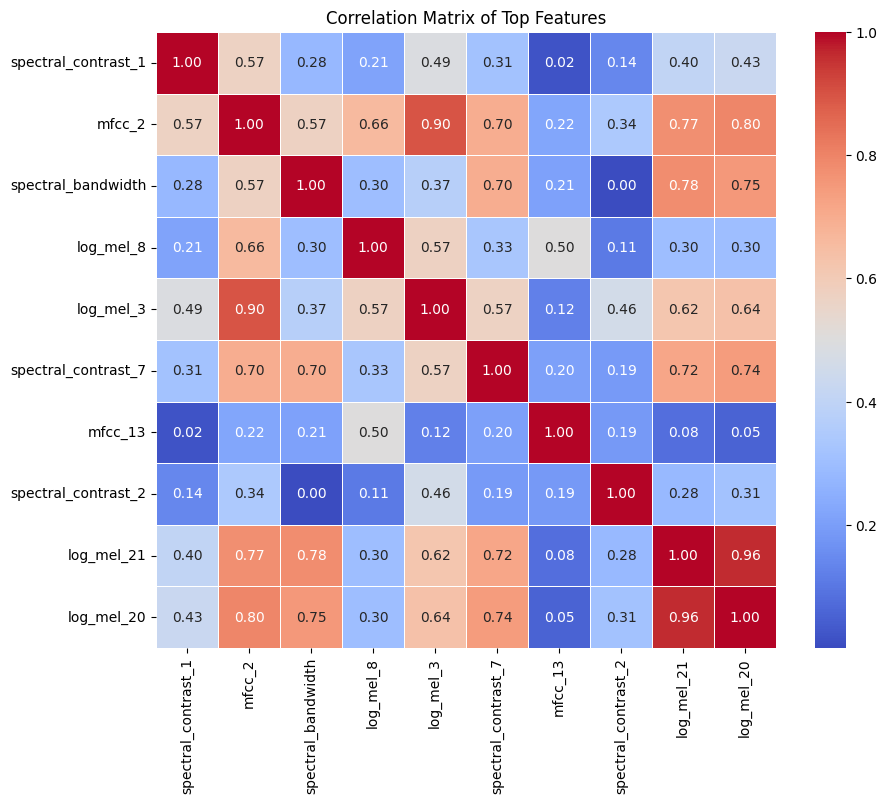

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(feature_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Top Features")
plt.show()


In [8]:
upper_triangle = feature_corr_matrix.where(np.triu(np.ones(feature_corr_matrix.shape), k=1).astype(bool))

drop_threshold = 0.9
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > drop_threshold)]
print("Features to drop due to high inter-correlation:", to_drop)

selected_features = [f for f in top_features if f not in to_drop]
print("Final selected features:", selected_features)


Features to drop due to high inter-correlation: ['log_mel_20']
Final selected features: ['spectral_contrast_1', 'mfcc_2', 'spectral_bandwidth', 'log_mel_8', 'log_mel_3', 'spectral_contrast_7', 'mfcc_13', 'spectral_contrast_2', 'log_mel_21']


In [ ]:
X_selected = df[selected_features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)
kmeans = KMeans(n_clusters=2, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

Adjusted Rand Index: 0.19421940002831337


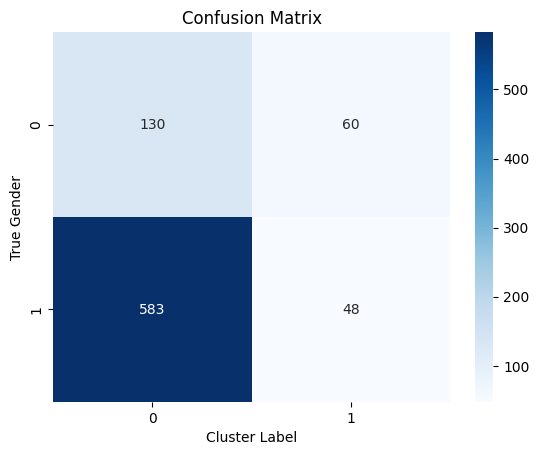

In [ ]:
true_labels = df['gender'] 
ari = adjusted_rand_score(true_labels, cluster_labels)
print("Adjusted Rand Index:", ari)

cm = confusion_matrix(true_labels, cluster_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Cluster Label")
plt.ylabel("True Gender")
plt.title("Confusion Matrix")
plt.show()

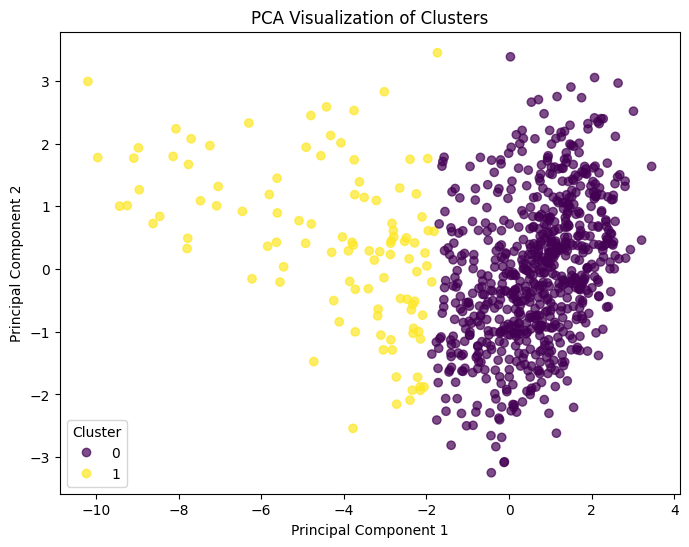

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Clusters")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()


the scores were not that good so now we do the clustering based on the features with the best pca scores with a correlation lower than a certain threshold

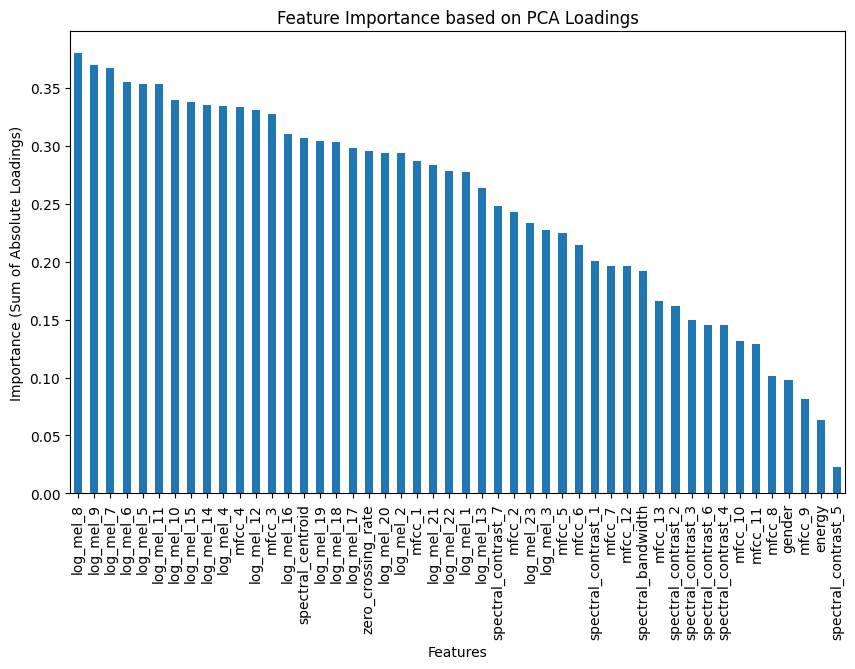

In [17]:
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df)

pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_features)

df_pca = pd.DataFrame(principal_components, columns=["PC1", "PC2"])

pca_loadings = pd.DataFrame(pca.components_, columns=df.columns, index=["PC1", "PC2"])
feature_importance = pca_loadings.abs().sum(axis=0).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feature_importance.plot(kind="bar")
plt.title("Feature Importance based on PCA Loadings")
plt.xlabel("Features")
plt.ylabel("Importance (Sum of Absolute Loadings)")
plt.xticks(rotation=90)
plt.show()



In [18]:
top_features = feature_importance.head(10).index.tolist()
X_top = df[top_features]
feature_corr_matrix = X_top.corr().abs()
print(top_features)

['log_mel_8', 'log_mel_9', 'log_mel_7', 'log_mel_6', 'log_mel_5', 'log_mel_11', 'log_mel_10', 'log_mel_15', 'log_mel_14', 'log_mel_4']


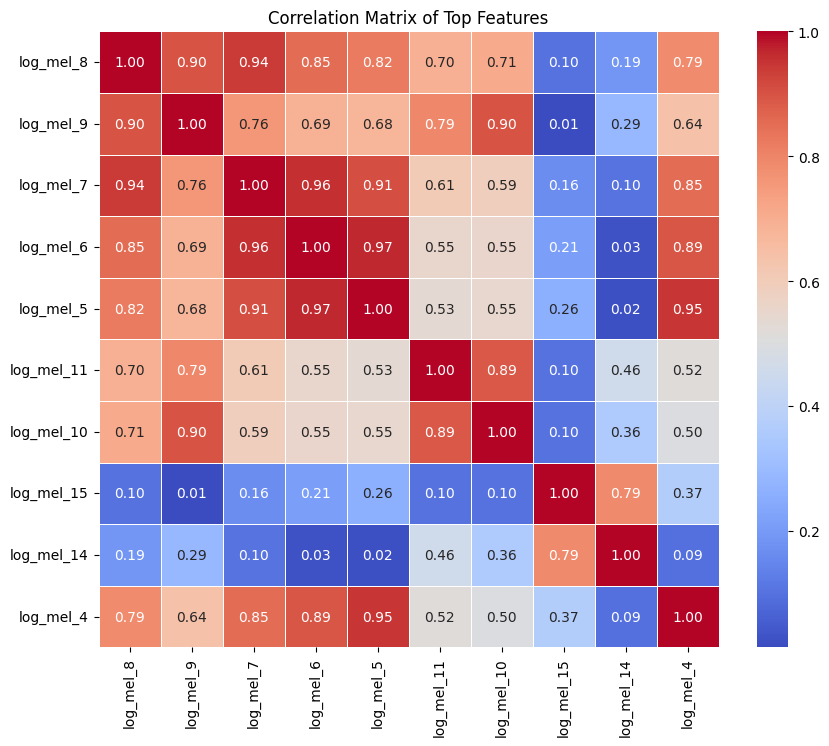

In [19]:
plt.figure(figsize=(10, 8))
sns.heatmap(feature_corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Top Features")
plt.show()


In [20]:
upper_triangle = feature_corr_matrix.where(np.triu(np.ones(feature_corr_matrix.shape), k=1).astype(bool))

drop_threshold = 0.9
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > drop_threshold)]
print("Features to drop due to high inter-correlation:", to_drop)

selected_features = [f for f in top_features if f not in to_drop]
print("Final selected features:", selected_features)


Features to drop due to high inter-correlation: ['log_mel_7', 'log_mel_6', 'log_mel_5', 'log_mel_4']
Final selected features: ['log_mel_8', 'log_mel_9', 'log_mel_11', 'log_mel_10', 'log_mel_15', 'log_mel_14']


In [21]:
X_selected = df[selected_features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)
kmeans = KMeans(n_clusters=2, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

Adjusted Rand Index: 0.02124541698259772


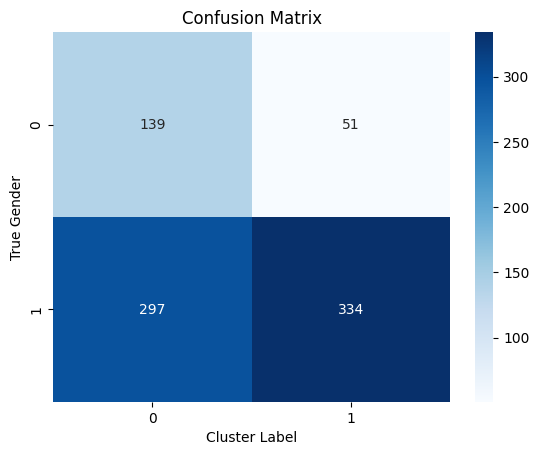

In [22]:
true_labels = df['gender'] 
ari = adjusted_rand_score(true_labels, cluster_labels)
print("Adjusted Rand Index:", ari)

cm = confusion_matrix(true_labels, cluster_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Cluster Label")
plt.ylabel("True Gender")
plt.title("Confusion Matrix")
plt.show()

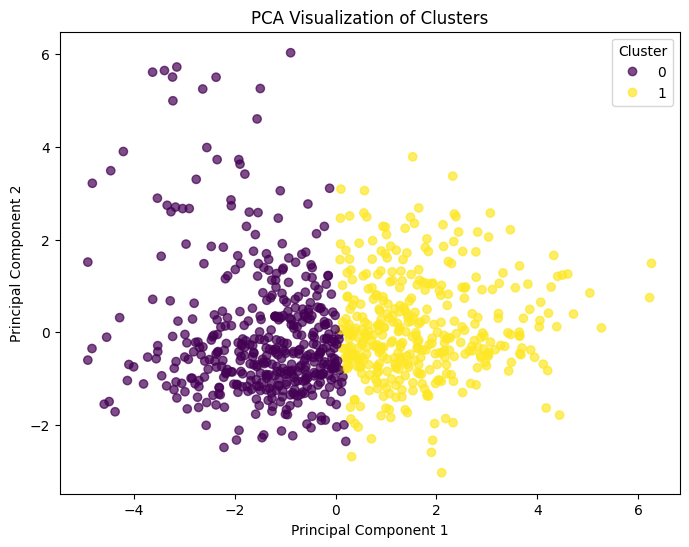

In [23]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Clusters")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()
